In [ ]:
pip install astropy astroquery numpy matplotlib imageio reproject

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 78.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 73.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 47.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.2 MB/s  0:00:00
  Created wheel for pims: filename=pims-0.7-py3-none-any.whl size=84644 sha256=e23525ff1ddf2a00c24bdf96f580bfa272d5c9976ac6f2f3703babf85cfc8d89
  Stored in directory: /root/.cache/pip/wheels/9b/9e/a8/a0f41cf12a4a7b98a501ad8590595e2071a946d2fd33b0eb60
Successfully built pims
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [astroquery]


In [ ]:
"""
SPHEREx cutout pipeline
=======================

What this script does, in plain English
---------------------------------------
SPHEREx is a NASA space telescope that photographs the whole sky in infrared
light, split into many narrow colours (wavelengths).  For one chosen target
(a star, say), this script:

  1. Works out where the target is on the sky (from its name or coordinates).
  2. Asks the IRSA archive which SPHEREx exposures cover that spot.
  3. Downloads a small square image ("cutout") around the target from each.
  4. Measures how bright the target is in each cutout.
  5. Re-draws every cutout on one shared grid, north up, so they line up.
  6. Saves a contact sheet of the images and a brightness-vs-wavelength plot.

Mini-glossary
-------------
RA / Dec        Sky coordinates, like longitude / latitude.  RA is 0-360
                degrees (or 0-24 hours); Dec is -90 to +90 degrees.
J2000           The coordinates are quoted "as of the year 2000".
Proper motion   Nearby stars drift across the sky.  Our target moves ~8
                arcseconds per year, so we must correct its position for the
                date of each exposure.  (1 arcsecond = 1/3600 of a degree.)
IRSA / SIA      IRSA is NASA's infrared data archive.  SIA (Simple Image
                Access) is the web service we use to search it.
FITS            The standard astronomy image file format.  One file holds
                several named layers ("extensions"): IMAGE, VARIANCE, ...
WCS             "World Coordinate System": the recipe that converts between
                pixel positions (x, y) and sky positions (RA, Dec).
Band            SPHEREx has six detectors, D1..D6.  Each sees a different
                range of wavelengths, so together they give a rough spectrum.
Flux            Brightness.  The images are in MJy/sr (brightness per patch
                of sky); we convert the target's total to microjanskys (uJy).
Aperture        A small circle around the target.  We add up the light inside
                it and subtract the sky glow measured in a ring around it.
PSF             The blur a telescope makes of a point-like star.
Zodiacal light  Sunlight scattered by dust in our solar system.  It is a
                bright, uneven glow that we must subtract before measuring.
Flags           Each pixel carries a number whose bits mark problems
                (bad pixel, cosmic ray, ...).  We ignore pixels with bad bits.
"""

import hashlib
import io
import time
import warnings
from collections import Counter
from dataclasses import dataclass
from pathlib import Path
from typing import NamedTuple, Optional

import astropy.units as u
import numpy as np
import requests
from astropy import log as astropy_log
from astropy.coordinates import Angle, SkyCoord
from astropy.coordinates.name_resolve import NameResolveError
from astropy.io import fits
from astropy.io.votable import parse_single_table
from astropy.table import Table, vstack
from astropy.time import Time
from astropy.wcs import WCS

# Silence two harmless sources of console noise.
try:
    from erfa import ErfaWarning
    warnings.filterwarnings("ignore", category=ErfaWarning)
except ImportError:
    pass
astropy_log.setLevel("ERROR")  # WCS(..., key="W") logs an INFO line every call

try:
    from reproject import reproject_interp
except ImportError:  # install with: pip install reproject
    reproject_interp = None


# ==========================================================================
# Settings: edit these to change what the script does
# ==========================================================================

# The target.  If TARGET_NAME resolves, it is used.  Otherwise we fall back to
# the coordinates below.  Hand-typed coordinates MUST be J2000: positions baked
# into designations like "085510.83-071442.5" are for the discovery date, and
# for a star moving 8"/yr that is ~85" away from the J2000 position.
TARGET_NAME = "WISE J085510.83-071442.5"
FALLBACK_RA = "133.818908"    # degrees; same spot as "08h55m16.5s" or "08:55:16.5" (hours)
FALLBACK_DEC = "-7.247048"    # degrees; same spot as "-07d14m49.4s" or "-07:14:49.4"

# Proper motion of the target, in milliarcseconds per year (WISE 0855).
PM_RA = -8123.7 * u.mas / u.yr    # along RA (already scaled by cos(Dec))
PM_DEC = 673.2 * u.mas / u.yr

FIELD_OF_VIEW_DEG = 0.2      # width of the final aligned images
SEARCH_RADIUS_DEG = 0.02     # archive search circle (see note in main())

# Cutouts are ~4 MB each.  Set to None to use every exposure (needed for
# stacking, slower to download).
MAX_FRAMES_PER_BAND = 6

# The six SPHEREx detectors.
BANDS = ("SPHEREx-D1", "SPHEREx-D2", "SPHEREx-D3",
         "SPHEREx-D4", "SPHEREx-D5", "SPHEREx-D6")

# Archive details.
SIA_URL = "https://irsa.ipac.caltech.edu/SIA"
COLLECTIONS = ("spherex_dr1", "spherex_qr3")
RETRY_STATUS_CODES = (502, 503, 504)   # "server busy / gateway problem"
CUTOUT_CACHE_DIR = "cutout_cache"

# Measuring brightness.  The PSF is 3.1" wide but one pixel is 6.15", so a
# star is barely spread over more than one pixel.  Measured on bright stars,
# ~80% of the light falls within 2 pixels (12") of the centre, so we add up
# the pixels within 2 px and multiply by 1.25 to recover the missing light.
# This is a relative measurement, contaminated by anything within ~12".
APERTURE_RADIUS_PX = 2.0
APERTURE_CORRECTION = 1.25

# Flag bits that are normal, not problems.  Every other bit marks a bad pixel.
BENIGN_FLAGS = {"SOURCE", "FULLSAMPLE"}


# ==========================================================================
# Step 1: where is the target?
# ==========================================================================

def parse_angle_deg(text: str, label: str, bare_unit) -> float:
    """Convert text like "133.8", "08h55m10.8s" or "08:55:10.8" to degrees.

    A plain number is always degrees.  Colon/space-separated values have no
    units written out, so they are read in `bare_unit` (hours for RA,
    degrees for Dec, by astronomical convention).
    """
    text = text.strip()
    if not text:
        raise ValueError(f"{label} is empty")

    try:
        degrees = float(text)
    except ValueError:
        degrees = _angle_to_deg(text)                   # units written in text
        if degrees is None:
            degrees = _angle_to_deg(text, bare_unit)    # colon-separated
        if degrees is None:
            raise ValueError(f"cannot parse {label} {text!r}")

    if not np.isfinite(degrees):
        raise ValueError(f"{label} is not finite: {text!r}")
    return degrees


def _angle_to_deg(text, unit=None):
    """Parse with astropy; return None instead of raising if it fails."""
    try:
        return Angle(text, unit=unit).to_value(u.deg)
    except (ValueError, u.UnitsError):
        return None


def make_target(ra_text: str, dec_text: str) -> SkyCoord:
    """Build a sky position from RA and Dec given as text."""
    ra = parse_angle_deg(ra_text, "RA", u.hourangle) % 360.0
    if ra == 360.0:     # tiny negative inputs can round up to exactly 360
        ra = 0.0
    dec = parse_angle_deg(dec_text, "Dec", u.deg)
    if not -90.0 <= dec <= 90.0:
        raise ValueError(f"Dec out of range: {dec}")
    return SkyCoord(ra=ra * u.deg, dec=dec * u.deg, frame="icrs")


def resolve_name(name: str) -> SkyCoord:
    """Look a name up in the Sesame service (returns J2000 coordinates)."""
    name = name.strip()
    if not name:
        raise ValueError("name is empty")
    try:
        coord = SkyCoord.from_name(name)
    except NameResolveError as exc:
        raise ValueError(
            f"name not found: {name!r}. Try the canonical designation "
            f"(e.g. 'WISE J085510.83-071442.5') or enter RA/Dec directly."
        ) from exc
    if not (np.isfinite(coord.ra.deg) and np.isfinite(coord.dec.deg)):
        raise ValueError(f"resolved non-finite coordinate for {name!r}")
    return coord


def find_target() -> SkyCoord:
    """Use TARGET_NAME if it resolves, otherwise the fallback coordinates."""
    if TARGET_NAME:
        try:
            target = resolve_name(TARGET_NAME)
            print(f"{TARGET_NAME} -> J2000 {target.ra.deg:.6f} {target.dec.deg:.6f}")
            return target
        except ValueError as exc:
            print(exc)
            print("falling back to the J2000 coordinates in FALLBACK_RA/FALLBACK_DEC")
    return make_target(FALLBACK_RA, FALLBACK_DEC)


def target_position_at(target: SkyCoord, when: Time) -> SkyCoord:
    """Where is the target at time `when`?  Applies the proper motion above.

    Example: WISE 0855 moves about -8.12" in RA per year, so ten years after
    J2000 it sits ~81" away from its J2000 position.
    """
    moving = SkyCoord(ra=target.ra, dec=target.dec,
                      pm_ra_cosdec=PM_RA, pm_dec=PM_DEC,
                      obstime=Time("J2000"), frame="icrs")
    return moving.apply_space_motion(new_obstime=when)


# ==========================================================================
# Step 2: ask the archive which exposures cover the target
# ==========================================================================

def query_sia(ra_deg, dec_deg, radius_deg, collections=COLLECTIONS) -> Table:
    """Search every collection and stack the results into one table.

    Each row of the result is one exposure image.  Collections are queried
    one at a time: smaller responses and clearer error messages.
    """
    tables = []
    for collection in collections:
        try:
            table = _query_one_collection(collection, ra_deg, dec_deg, radius_deg)
        except RuntimeError as exc:
            print(f"  {collection}: {exc}")
            continue
        print(f"  {collection}: {len(table)} rows")
        if len(table) > 0:
            tables.append(table)

    if not tables:
        raise RuntimeError("the archive returned no exposures")
    return vstack(tables)


def _query_one_collection(collection, ra_deg, dec_deg, radius_deg,
                          attempts=3, timeout=(10, 60)) -> Table:
    """One plain web request to IRSA's SIA service, with retries."""
    params = {
        "COLLECTION": collection,
        "POS": f"CIRCLE {ra_deg:.6f} {dec_deg:.6f} {radius_deg:.6f}",
        "RESPONSEFORMAT": "votable",
    }
    for attempt in range(1, attempts + 1):
        started = time.time()
        try:
            response = requests.get(SIA_URL, params=params, timeout=timeout)
        except (requests.Timeout, requests.ConnectionError) as exc:
            print(f"  [{attempt}/{attempts}] {type(exc).__name__} "
                  f"after {time.time() - started:.0f}s")
            time.sleep(5 * attempt)
            continue

        print(f"  [{attempt}/{attempts}] HTTP {response.status_code}, "
              f"{len(response.content)} bytes in {time.time() - started:.0f}s")

        if response.status_code == 200:
            return _votable_to_table(response.content)
        if response.status_code in RETRY_STATUS_CODES:
            time.sleep(5 * attempt)
            continue
        response.raise_for_status()      # e.g. 400 = our parameters are wrong

    raise RuntimeError("archive unavailable after several attempts")


def _votable_to_table(content: bytes) -> Table:
    """Parse the archive's VOTable (XML) answer into an astropy Table."""
    votable = parse_single_table(io.BytesIO(content))
    table = votable.to_table()
    # IRSA gives each column an ID like "col_15" next to its real name
    # (e.g. "access_url"); astropy keys off the ID, so put the names back.
    table.rename_columns(table.colnames, [field.name for field in votable.fields])
    return table


def get_exposures(position: SkyCoord, radius_deg: float, cache_path: Path) -> Table:
    """Return the exposure list, from the cache file if we already have it."""
    if cache_path.exists():
        table = Table.read(cache_path)
        print(f"loaded {len(table)} rows from {cache_path}")
        return table

    table = query_sia(position.ra.deg, position.dec.deg, radius_deg)
    table.write(cache_path, format="ecsv", overwrite=True)
    print(f"wrote {len(table)} rows to {cache_path}")
    return table


# ==========================================================================
# Step 3: download cutouts and read their contents
# ==========================================================================

class NotCovered(Exception):
    """The target is not on this exposure (the server answered HTTP 422)."""


def fetch_cutout(access_url, ra_deg, dec_deg, size_deg,
                 cache_dir=None, attempts=3) -> fits.HDUList:
    """Download a square cutout (a FITS file) centred on a sky position.

    Downloaded files are saved in `cache_dir`, so re-running is fast.
    """
    url = f"{access_url}?center={ra_deg:.7f},{dec_deg:.7f}&size={size_deg}"

    cache_file = None
    if cache_dir is not None:
        cache_file = Path(cache_dir) / (hashlib.md5(url.encode()).hexdigest() + ".fits")
        if cache_file.exists():
            return fits.open(cache_file)

    for attempt in range(1, attempts + 1):
        try:
            response = requests.get(url, timeout=120)
        except requests.RequestException:
            if attempt == attempts:
                raise
            time.sleep(2 ** attempt)
            continue

        if response.status_code == 200:
            if not response.content.startswith(b"SIMPLE"):   # every FITS file starts so
                raise OSError(f"not a FITS file from {access_url}")
            if cache_file is not None:
                cache_file.parent.mkdir(parents=True, exist_ok=True)
                cache_file.write_bytes(response.content)
            return fits.open(io.BytesIO(response.content))

        if response.status_code == 422:
            raise NotCovered(f"position off footprint: {access_url}")

        if response.status_code in RETRY_STATUS_CODES:
            if attempt == attempts:
                response.raise_for_status()
            time.sleep(5 * attempt)
            continue

        response.raise_for_status()


def flag_names(header) -> dict:
    """Map each flag bit value to its name, e.g. {1: "TRANSIENT", 2: ...}."""
    names = {}
    for i in range(64):
        if f"MSKM{i:04d}" in header:
            bit_value = int(header[f"MSKM{i:04d}"])
            names[bit_value] = header[f"MSKN{i:04d}"].strip().upper()
    return names


def bad_bits(header) -> int:
    """Combine every flag bit that is a real problem into one number."""
    combined = 0
    for bit_value, name in flag_names(header).items():
        if name not in BENIGN_FLAGS:
            combined |= bit_value
    return combined


def describe_flags(value: int, names: dict) -> str:
    """Turn a pixel's flag number into text like "SOURCE+FULLSAMPLE"."""
    active = [name for bit, name in sorted(names.items()) if value & bit]
    return "+".join(active) or "0"


def pixel_area_sr(header) -> float:
    """Sky area of one pixel in steradians (sr).

    The header gives it in arcsec^2.  Example with the typical 37.86 arcsec^2:
      1 arcsec = pi / 180 / 3600 = 4.848e-6 radians
      1 arcsec^2 = (4.848e-6)^2 = 2.350e-11 sr
      37.86 arcsec^2 = 37.86 * 2.350e-11 = 8.899e-10 sr
    """
    area_arcsec2 = float(header.get("OMEGA_MEDIAN", 37.86))
    return area_arcsec2 * (np.pi / 180.0 / 3600.0) ** 2


def to_microjansky(mjy_per_sr_sum: float, area_sr: float) -> float:
    """Convert a sum of pixel values (MJy/sr) into microjanskys.

    Worked example: pixel values in the aperture add up to 0.10 MJy/sr.
      0.10 MJy/sr * 8.899e-10 sr   = 8.899e-11 MJy   (sr cancels)
      8.899e-11 MJy * 1e12 uJy/MJy = 88.99 uJy       (1 MJy = 1e12 uJy)
      88.99 uJy * 1.25             = 111.2 uJy       (aperture correction)
    """
    return mjy_per_sr_sum * area_sr * 1e12 * APERTURE_CORRECTION


def wavelength_at_pixel(hdul, x: float, y: float):
    """Wavelength (and its bandwidth) seen by pixel (x, y), in microns.

    Each pixel sees a slightly different colour.  The file stores this as a
    second, "alternate" WCS (key "W") with a lookup table.  The colour changes
    along the detector's y direction, not x, so we let astropy read the table
    instead of interpolating by hand.
    """
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # noisy but harmless
        wave_wcs = WCS(hdul["IMAGE"].header, key="W", fobj=hdul)
        wavelength, bandwidth = wave_wcs.pixel_to_world(x, y)
    return float(wavelength.to_value(u.micron)), float(bandwidth.to_value(u.micron))


# ==========================================================================
# Step 4: measure brightness
# ==========================================================================
# In these functions `x, y` is the target's pixel position, and `d` is every
# pixel's distance from it, so (d <= 2) is "a circle of radius 2 pixels".

class Photometry(NamedTuple):
    flux: float              # light inside the aperture, sky removed (MJy/sr, summed)
    error: float             # uncertainty on flux
    background: float        # typical sky level in the ring
    background_noise: float  # pixel-to-pixel scatter of the sky


def aperture_photometry(image, variance, flags, bad, x, y,
                        aperture_radius=APERTURE_RADIUS_PX,
                        ring_inner=6.0, ring_outer=12.0) -> Optional[Photometry]:
    """Add up the light in a circle, after subtracting the sky from a ring.

    `image` must already have the zodiacal light removed: that glow is
    0.2-0.7 MJy/sr here, so even a slight slope across the ~13 aperture
    pixels would be bigger than the star itself.

    Returns None if there are too few good pixels to measure.
    """
    height, width = image.shape
    yy, xx = np.mgrid[0:height, 0:width]          # pixel coordinate grids
    d = np.hypot(xx - x, yy - y)

    usable = (np.isfinite(image) & np.isfinite(variance) & (variance > 0)
              & ((flags & bad) == 0))
    ring = (d >= ring_inner) & (d <= ring_outer) & usable
    if ring.sum() < 20:                            # small cutouts: use a closer ring
        ring = (d >= 4) & (d <= 15) & usable
    aperture = (d <= aperture_radius) & usable
    if aperture.sum() == 0 or ring.sum() < 20:
        return None

    sky_pixels = image[ring]
    background = float(np.median(sky_pixels))
    # 1.4826 * median absolute deviation = a robust estimate of the scatter
    background_noise = 1.4826 * float(np.median(np.abs(sky_pixels - background)))

    flux = float(np.sum(image[aperture] - background))
    # Errors add in quadrature: the archive's per-pixel variance, plus the sky
    # scatter once for each aperture pixel.
    error = float(np.sqrt(np.sum(variance[aperture])
                          + aperture.sum() * background_noise ** 2))
    return Photometry(flux, error, background, background_noise)


def peak_pixel_snr(image, variance, ix, iy, phot: Photometry) -> float:
    """Signal-to-noise of the single brightest-pixel position (ix, iy).

    With a 3.1" PSF in 6.15" pixels this is the honest detection test: an
    aperture sum over 13 noisy pixels can reach S/N 3 by chance even when no
    source is there.
    """
    pixel_variance = variance[iy, ix]
    if not np.isfinite(pixel_variance):
        pixel_variance = 0.0
    noise = np.sqrt(max(pixel_variance, 0.0) + phot.background_noise ** 2)
    return float((image[iy, ix] - phot.background) / noise)


def centroid_offset(image, flags, bad, x, y, radius=3.0):
    """Brightness-weighted centre near (x, y), as an offset (dx, dy) in pixels.

    This is a contamination check, not a measurement.  Since the PSF is only
    ~1.2 px wide, a centre 1-2 px from where the target should be means
    another object is blended into the same aperture.
    Returns None if there is too little data.
    """
    height, width = image.shape
    yy, xx = np.mgrid[0:height, 0:width]
    d = np.hypot(xx - x, yy - y)

    usable = np.isfinite(image) & ((flags & bad) == 0)
    ring = (d >= 5) & (d <= 9) & usable
    if ring.sum() < 10:
        return None
    background = float(np.median(image[ring]))

    # np.where rather than mask * array: one NaN pixel would turn
    # 0 * NaN into NaN and ruin the whole sum.
    weight = np.where((d <= radius) & usable,
                      np.clip(image - background, 0, None), 0.0)
    if weight.sum() <= 0:
        return None
    return (float((weight * xx).sum() / weight.sum() - x),
            float((weight * yy).sum() / weight.sum() - y))


# ==========================================================================
# One exposure -> one Frame
# ==========================================================================

@dataclass
class Frame:
    """Everything we know about the target in one exposure."""
    band: str                    # e.g. "SPHEREx-D3"
    obs_id: str
    mjd: float                   # observation date (Modified Julian Date)
    obs_time: Time
    wavelength_um: float         # colour at the target's pixel, in microns
    bandwidth_um: float
    image: np.ndarray            # sky image, zodiacal light removed (MJy/sr)
    variance: np.ndarray         # per-pixel noise^2
    flags: np.ndarray            # per-pixel problem bits
    wcs: WCS                     # pixel <-> sky conversion for this image
    bad_bits: int
    target_flag: int             # flag value at the target's pixel
    target_flag_names: str
    shift_ra_deg: float          # how far the target moved since the reference date
    shift_dec_deg: float
    pixel_scale_arcsec: float
    centroid_offset_px: Optional[tuple]

    # Measurements (NaN if the frame had too few good pixels)
    flux_ujy: float = np.nan
    err_ujy: float = np.nan
    peak_snr: float = np.nan

    # Filled in later by align_frames()
    image_aligned: Optional[np.ndarray] = None
    variance_aligned: Optional[np.ndarray] = None
    flags_aligned: Optional[np.ndarray] = None
    footprint: Optional[np.ndarray] = None

    @property
    def band_label(self) -> str:
        return self.band[-2:]                     # "D3"

    @property
    def snr(self) -> float:
        return self.flux_ujy / self.err_ujy if self.err_ujy > 0 else np.nan

    @property
    def offset_arcsec(self) -> float:
        if self.centroid_offset_px is None:
            return np.nan
        return self.pixel_scale_arcsec * float(np.hypot(*self.centroid_offset_px))

    @property
    def bad_pixel_percent(self) -> float:
        return 100.0 * float(np.mean((self.flags & self.bad_bits) != 0))


def load_frame(row, band, target, reference, cutout_size_deg) -> Optional[Frame]:
    """Download one cutout and measure the target in it.

    `row` is one line of the archive's exposure table.  `reference` is the
    target's position at the median observation date; every cutout is centred
    there.  Returns None (after printing why) if the exposure can't be used.
    """
    try:
        hdul = fetch_cutout(row["access_url"], reference.ra.deg, reference.dec.deg,
                            cutout_size_deg, cache_dir=CUTOUT_CACHE_DIR)
    except NotCovered:
        print("  skip (off footprint):", row["obs_id"])
        return None
    except (requests.HTTPError, OSError) as exc:
        print("  skip (HTTP):", row["obs_id"], exc)
        return None

    with hdul:   # closes the file when we leave this block
        header = hdul["IMAGE"].header
        wcs = WCS(header)                      # keep the SIP distortion terms

        # Where is the target *in this exposure*?  It moves up to 8"/yr, so
        # we re-compute its position for each exposure's date.
        obs_time = Time(row["t_min"], format="mjd")
        position = target_position_at(target, obs_time)
        x, y = wcs.world_to_pixel(position)
        x, y = float(x), float(y)
        ix, iy = int(round(x)), int(round(y))

        width, height = header["NAXIS1"], header["NAXIS2"]
        if not (0 <= ix < width and 0 <= iy < height):
            # Near a detector edge the archive returns a thin sliver that
            # does not actually contain the target.
            print(f"  skip (target off detector): {row['obs_id']} "
                  f"cutout {width}x{height}, pixel ({x:.0f}, {y:.0f})")
            return None

        flags = np.array(hdul["FLAGS"].data, dtype=np.int32)
        variance = np.array(hdul["VARIANCE"].data, dtype=float)
        image = np.array(hdul["IMAGE"].data, dtype=float)

        # Subtract the zodiacal-light model (0.18-0.68 MJy/sr here: far
        # brighter than the target, and not flat), or we would be measuring
        # the slope of the sky glow rather than the star.
        if "ZODI" in hdul:
            image -= np.array(hdul["ZODI"].data, dtype=float)

        names = flag_names(hdul["FLAGS"].header)
        bad = bad_bits(hdul["FLAGS"].header)
        wavelength, bandwidth = wavelength_at_pixel(hdul, x, y)

        # Brightness, converted from MJy/sr to microjanskys.
        flux_ujy = err_ujy = peak_snr = np.nan
        phot = aperture_photometry(image, variance, flags, bad, x, y)
        if phot is not None:
            area_sr = pixel_area_sr(header)
            flux_ujy = to_microjansky(phot.flux, area_sr)
            err_ujy = to_microjansky(phot.error, area_sr)
            peak_snr = peak_pixel_snr(image, variance, ix, iy, phot)

        return Frame(
            band=band,
            obs_id=row["obs_id"],
            mjd=float(row["t_min"]),
            obs_time=obs_time,
            wavelength_um=wavelength,
            bandwidth_um=bandwidth,
            image=image,
            variance=variance,
            flags=flags,
            wcs=wcs,
            bad_bits=bad,
            target_flag=int(flags[iy, ix]),
            target_flag_names=describe_flags(int(flags[iy, ix]), names),
            shift_ra_deg=position.ra.deg - reference.ra.deg,
            shift_dec_deg=position.dec.deg - reference.dec.deg,
            # arcsec/pixel, taken from the archive table (simpler than
            # unpacking the WCS, which returns mixed types depending on file)
            pixel_scale_arcsec=float(row["s_pixel_scale"]),
            centroid_offset_px=centroid_offset(image, flags, bad, x, y),
            flux_ujy=flux_ujy,
            err_ujy=err_ujy,
            peak_snr=peak_snr,
        )


def download_frames(exposures, bands_present, target, reference, cutout_size_deg):
    """Load frames for every band, oldest exposures first."""
    frames = []
    for band in bands_present:
        rows = exposures[exposures["energy_bandpassname"] == band]
        rows = rows[np.argsort(np.asarray(rows["t_min"], dtype=float))]
        if MAX_FRAMES_PER_BAND is not None:
            rows = rows[:MAX_FRAMES_PER_BAND]
        print(f"\n{band}: {len(rows)} frames")

        for row in rows:
            frame = load_frame(row, band, target, reference, cutout_size_deg)
            if frame is not None:
                frames.append(frame)

    frames.sort(key=lambda f: (f.band, f.mjd))
    return frames


# ==========================================================================
# Step 5: line all the images up, north up
# ==========================================================================

def north_up_wcs(ra, dec, fov_deg, pixel_scale_arcsec=6.1577):
    """Build the shared output grid: square, centred on (ra, dec), north up.

    Example: a 0.2 degree field is 0.2 * 3600 = 720 arcsec wide, and
    720 / 6.1577 = 116.9, so the grid is 117 x 117 pixels.
    """
    n = int(round(fov_deg * 3600.0 / pixel_scale_arcsec))
    scale_deg = pixel_scale_arcsec / 3600.0

    w = WCS(naxis=2)
    w.wcs.ctype = ["RA---TAN", "DEC--TAN"]
    w.wcs.crpix = [(n + 1) / 2.0, (n + 1) / 2.0]     # reference pixel: the centre
    w.wcs.crval = [ra, dec]                           # ...which sits at this sky spot
    w.wcs.cd = np.array([[-scale_deg, 0.0],           # minus sign: RA grows to the left
                         [0.0, scale_deg]])
    w.wcs.radesys = "ICRS"
    return w, n


def shifted_wcs(wcs, shift_ra_deg, shift_dec_deg):
    """Copy of a WCS, nudged so a moved star stays on the same pixel.

    The shift is only arcseconds, so simply adding it to the reference sky
    position is accurate to well under one pixel.
    """
    shifted = wcs.deepcopy()
    shifted.wcs.crval = [shifted.wcs.crval[0] + shift_ra_deg,
                         shifted.wcs.crval[1] + shift_dec_deg]
    return shifted


def align_frames(frames, ra, dec):
    """Resample every frame onto one common grid (stored in frame.*_aligned)."""
    out_wcs, n = north_up_wcs(ra, dec, FIELD_OF_VIEW_DEG)
    print(f"\noutput grid: {n}x{n} px, 6.1577\"/px, north up")

    for frame in frames:
        # Register on the moving target, not the background stars, so the
        # target lands on the same pixel in every epoch.
        wcs = shifted_wcs(frame.wcs, frame.shift_ra_deg, frame.shift_dec_deg)

        frame.image_aligned, frame.footprint = reproject_interp(
            (frame.image, wcs), out_wcs, shape_out=(n, n))
        frame.variance_aligned, _ = reproject_interp(
            (frame.variance, wcs), out_wcs, shape_out=(n, n))
        flags_float, _ = reproject_interp(
            (frame.flags, wcs), out_wcs, shape_out=(n, n), order="nearest-neighbor")
        # Pixels outside the footprint are NaN, which would cast to garbage.
        frame.flags_aligned = np.nan_to_num(flags_float, nan=0.0).round().astype(np.int32)

    fully_covered = [f for f in frames if f.footprint.mean() > 0.99]
    print(f"{len(fully_covered)}/{len(frames)} frames fully cover the output grid")


def alignment_scatter(frames, half=5, edge=12):
    """Cheap alignment check: track the brightest star across the frames.

    Returns (mean offset, scatter) in pixels as (x, y) pairs, or (None, None).
    """
    stack = np.nanmedian([f.image_aligned for f in frames], axis=0)
    height, width = stack.shape

    # Find the brightest pixel, ignoring the image edges.
    core = stack[edge:height - edge, edge:width - edge]
    iy, ix = np.unravel_index(np.nanargmax(core), core.shape)
    iy += edge
    ix += edge

    y0, y1 = max(0, iy - half), min(height, iy + half + 1)
    x0, x1 = max(0, ix - half), min(width, ix + half + 1)
    ys, xs = np.mgrid[y0:y1, x0:x1]

    offsets = []
    for frame in frames:
        patch = frame.image_aligned[y0:y1, x0:x1]
        if not np.all(np.isfinite(patch)):
            continue
        weight = np.clip(patch - np.median(patch), 0, None)
        if weight.sum() <= 0:
            continue
        offsets.append(((weight * xs).sum() / weight.sum() - ix,
                        (weight * ys).sum() / weight.sum() - iy))

    if not offsets:
        return None, None
    offsets = np.array(offsets)
    return offsets.mean(axis=0), offsets.std(axis=0)


# ==========================================================================
# Printing and plotting
# ==========================================================================

def print_exposure_overview(exposures, t_min):
    """Show what the archive returned."""
    print(exposures["obs_id", "energy_bandpassname", "t_min"][:5])
    print("rows:", len(exposures))
    print("columns:", exposures.colnames)
    print("bands:", Counter(exposures["energy_bandpassname"]))
    first = Time(float(np.nanmin(t_min)), format="mjd").iso
    last = Time(float(np.nanmax(t_min)), format="mjd").iso
    print("t_min range:", first, "->", last)


def print_frame_table(frames):
    """One line per frame: when, what colour, how bright, how reliable."""
    n_bands = len({f.band for f in frames})
    print(f"\n{len(frames)} frames from {n_bands} bands")
    print(f"{'band':4} {'date':11} {'MJD':>10} {'lambda':>8} {'dlam':>6} "
          f"{'flux uJy':>9} {'err':>7} {'S/N':>6} {'peakSNR':>8} "
          f"{'off arcsec':>10} {'bad %':>6}  flag@target")
    for f in frames:
        print(f"{f.band_label:4} {f.obs_time.iso[:10]:11} {f.mjd:10.3f} "
              f"{f.wavelength_um:8.3f} {f.bandwidth_um:6.3f} "
              f"{f.flux_ujy:9.1f} {f.err_ujy:7.1f} {f.snr:6.1f} {f.peak_snr:8.1f} "
              f"{f.offset_arcsec:10.1f} {f.bad_pixel_percent:6.2f}  "
              f"{f.target_flag} {f.target_flag_names}")


def print_band_summary(frames):
    """One line per band, with a verdict on whether the target is isolated."""
    print(f"\n{'band':4} {'frames':>6} {'lambda sampled (um)':>28} "
          f"{'median off':>11}  verdict")
    for band in BANDS:
        in_band = [f for f in frames if f.band == band]
        if not in_band:
            continue
        wavelengths = np.array([f.wavelength_um for f in in_band])
        offsets = [f.offset_arcsec for f in in_band if not np.isnan(f.offset_arcsec)]
        median_offset = float(np.median(offsets)) if offsets else np.nan

        # One pixel is ~6.16" and the PSF only ~1.2 px, so an offset beyond
        # half a pixel means a different object sits in the aperture; it is
        # not just centroid error.
        half_pixel = 0.5 * in_band[0].pixel_scale_arcsec
        verdict = "blended/offset" if median_offset > half_pixel else "on target"
        print(f"{in_band[0].band_label:4} {len(in_band):6d} "
              f"{wavelengths.min():12.3f} -> {wavelengths.max():.3f} "
              f"{median_offset:9.1f}\"  {verdict}")


def print_alignment_checks(frames):
    """Report how well the bright star lines up from frame to frame."""
    for band in BANDS:
        in_band = [f for f in frames if f.band == band and f.image_aligned is not None]
        if len(in_band) < 3:
            continue
        mean_offset, scatter = alignment_scatter(in_band)
        if mean_offset is not None:
            print(f"{in_band[0].band_label}: bright-star centroid offset "
                  f"({mean_offset[0]:+.2f}, {mean_offset[1]:+.2f}) px, "
                  f"scatter ({scatter[0]:.2f}, {scatter[1]:.2f}) px")


def _get_pyplot():
    """Import matplotlib lazily, set up to draw into files (no window)."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    return plt


def save_contact_sheet(frames, path="contact_sheet.png", per_band=4):
    """A grid of thumbnails: one row per detector, one column per exposure."""
    plt = _get_pyplot()

    count = Counter(f.band for f in frames)
    bands = [b for b in BANDS if count[b] > 0]
    if not bands:
        return
    cols = min(per_band, max(count.values()))

    fig, axes = plt.subplots(len(bands), cols, squeeze=False,
                             figsize=(3.0 * cols, 2.9 * len(bands)))
    for ax in axes.ravel():
        ax.axis("off")                    # hide unused cells

    for row_i, band in enumerate(bands):
        in_band = [f for f in frames if f.band == band][:cols]
        for col_i, frame in enumerate(in_band):
            ax = axes[row_i, col_i]
            img = frame.image_aligned if frame.image_aligned is not None else frame.image
            low, high = np.nanpercentile(img, [5, 99])      # clip extremes for contrast
            img = np.where(np.isfinite(img), img, low)      # blank areas black, not white
            ax.imshow(img, origin="lower", cmap="gray", vmin=low, vmax=high)
            ax.set_title(f"{frame.band_label}  {frame.obs_time.iso[5:16]}  "
                         f"{frame.wavelength_um:.2f} um", fontsize=8)
            ax.axis("on")
            ax.set_xticks([])
            ax.set_yticks([])

    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)
    print("wrote", path)


def save_spectrum(frames, path="spectrum.png"):
    """Plot brightness against wavelength, one colour per detector."""
    plt = _get_pyplot()

    fig, ax = plt.subplots(figsize=(7, 4.5))
    for band in BANDS:
        measured = [f for f in frames if f.band == band and not np.isnan(f.flux_ujy)]
        if not measured:
            continue
        measured.sort(key=lambda f: f.wavelength_um)
        ax.errorbar([f.wavelength_um for f in measured],
                    [f.flux_ujy for f in measured],
                    yerr=[f.err_ujy for f in measured],
                    fmt="o", ms=5, capsize=2, label=measured[0].band_label)

    ax.axhline(0.0, color="0.7", lw=0.8)
    ax.set_xlabel("wavelength (um)")
    ax.set_ylabel("aperture flux (uJy)")
    ax.set_title("SPHEREx spectrum of the target")
    ax.legend(fontsize=8, ncol=3)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)
    print("wrote", path)


# ==========================================================================
# Main
# ==========================================================================

def main():
    # --- 1. Where is the target? -----------------------------------------
    target = find_target()
    ra, dec = target.ra.deg, target.dec.deg
    print(f"J2000 position: {ra:.6f} {dec:.6f}")

    # --- 2. Which exposures cover it? ------------------------------------
    # The archive search is an "intersects" test against each exposure's
    # footprint, so even a tiny circle returns every exposure covering the
    # target.  Measured on IRSA:
    #   r=0.005 deg -> 258 rows, 2.1 s      r=0.05 deg -> 263 rows, 3.3 s
    #   r=0.10  deg -> read timeout
    # So the radius does NOT set the field of view; the cutout size does.
    #
    # Search around where the target is *today*, since it moves a lot.
    now = Time.now()
    position_now = target_position_at(target, now)
    print(f"epoch {now.iso[:10]}: {position_now.ra.deg:.5f} {position_now.dec.deg:.5f}")

    cache_name = f"exposures_{ra:.3f}_{dec:.3f}.ecsv".replace("-", "m")
    exposures = get_exposures(position_now, SEARCH_RADIUS_DEG, Path(cache_name))

    t_min = np.asarray(exposures["t_min"], dtype=float)
    print_exposure_overview(exposures, t_min)

    # --- 3. Download a cutout around the target from each exposure -------
    # Centre every cutout on where the target is at the median observation date.
    reference_time = Time(float(np.nanmedian(t_min)), format="mjd")
    reference = target_position_at(target, reference_time)
    print(f"\nreference epoch {reference_time.iso[:10]}: "
          f"{reference.ra.deg:.5f} {reference.dec.deg:.5f}")

    # Download 1.5x the final field of view, leaving margin so the edges stay
    # filled after the images are shifted and resampled.
    cutout_size_deg = round(1.5 * FIELD_OF_VIEW_DEG, 3)
    frames_per_band = MAX_FRAMES_PER_BAND if MAX_FRAMES_PER_BAND else "all"
    print(f"cutout {cutout_size_deg} deg, {frames_per_band} frames per band")

    bands_present = [b for b in BANDS if np.any(exposures["energy_bandpassname"] == b)]
    missing = [b for b in BANDS if b not in bands_present]
    if missing:
        print("no exposures in:", ", ".join(missing))

    frames = download_1frames(exposures, bands_present, target, reference, cutout_size_deg)
    if not frames:
        raise SystemExit("no cutouts retrieved")

    # --- 4. Report the measurements --------------------------------------
    print_frame_table(frames)
    print_band_summary(frames)

    # --- 5. Align everything and make the plots --------------------------
    if reproject_interp is None:
        print("\nreproject is not installed: pip install reproject")
        print("frames are still in memory in the `frames` list")
    else:
        align_frames(frames, reference.ra.deg, reference.dec.deg)
        print_alignment_checks(frames)

    save_contact_sheet(frames)
    save_spectrum(frames)


if __name__ == "__main__":
    main()

WISE J085510.83-071442.5 -> J2000 133.818908 -7.247048
J2000 position: 133.818908 -7.247048
epoch 2026-11-14: 133.75779 -7.24202
  [1/3] HTTP 200, 566768 bytes in 2s
  spherex_dr1: 258 rows
  [1/3] HTTP 200, 27474 bytes in 1s
  spherex_qr3: 0 rows
wrote 258 rows to exposures_133.819_m7.247.ecsv
      obs_id      energy_bandpassname    t_min    
                                           d      
----------------- ------------------- ------------
2025W19_1B_0116_1          SPHEREx-D3 60800.700028
2025W19_1B_0116_1          SPHEREx-D6 60800.700028
2025W19_1B_0116_2          SPHEREx-D3 60800.701521
2025W19_1B_0116_2          SPHEREx-D6 60800.701521
2025W19_1B_0138_1          SPHEREx-D3 60800.834438
rows: 258
columns: ['s_ra', 's_dec', 'facility_name', 'instrument_name', 'dataproduct_subtype', 'calib_level', 'dataproduct_type', 'energy_bandpassname', 'energy_emband', 'obs_id', 's_resolution', 'em_min', 'em_max', 'em_res_power', 'proposal_title', 'access_url', 'access_format', 'access_estsiz

In [1]:
"""SPHEREx cutout pipeline: query SIA, fetch cutouts, align north-up.
"""

import functools
import hashlib
import io
import math
import random
import time
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import requests
import astropy.units as u
from astropy.coordinates import Angle, SkyCoord
from astropy.coordinates.name_resolve import NameResolveError
from astropy.io import fits
from astropy import log as astropy_log
from astropy.io.votable import parse_single_table
from astropy.table import Table, vstack
from astropy.time import Time
from astropy.wcs import WCS
from pyvo.dal.exceptions import DALAccessError
from pyvo.dal.sia2 import SIA2Service

try:
    from erfa import ErfaWarning
    warnings.filterwarnings("ignore", category=ErfaWarning)
except ImportError:
    pass

# WCS(hdr, key="W", ...) logs a SIP INFO message on every call.
astropy_log.setLevel("ERROR")

try:
    from reproject import reproject_interp
except ImportError:  # pip install reproject
    reproject_interp = None

SIA_URL = "https://irsa.ipac.caltech.edu/SIA"
COLLECTIONS = ("spherex_dr1", "spherex_qr3")

# SPHEREx has six detectors. Each one sees the same sky strip in a different
# wavelength window, and an exposure writes one row per detector that covered
# the target (two rows: the same column, two halves of the band split).
BANDS = ("SPHEREx-D1", "SPHEREx-D2", "SPHEREx-D3",
         "SPHEREx-D4", "SPHEREx-D5", "SPHEREx-D6")

# Cutouts are ~4 MB each; set to None to use every exposure (needed for stacking).
MAX_FRAMES_PER_BAND = 36

# Photometry.  The PSF FWHM is 3.1" but one pixel is 6.15", so a point source
# is barely resolved: measured on bright stars in these frames, ~80% of the
# flux falls inside r=2 px (12"), and ~85% inside 3 px.  The aperture is
# therefore r=2 px with a fixed correction; it is a relative measurement and is
# contaminated by anything within ~12".
APERTURE_R_PX = 2.0
APERTURE_CORRECTION = 1.25

# Flag bits that are normal, not artefacts. Everything else marks a bad pixel.
BENIGN_FLAGS = {"SOURCE", "FULLSAMPLE"}

In [2]:
# --------------------------------------------------------------------------
# input validation
# --------------------------------------------------------------------------

def parse_ra(text: str) -> float:
    text = text.strip()
    if not text:
        raise ValueError("RA is empty")

    try:
        value = float(text)                      # "133.79513", "nan", "inf"
    except ValueError:
        try:
            value = Angle(text).to_value(u.deg)  # "08h55m10.831s", "-07d14m42.53s"
        except (ValueError, u.UnitsError):
            # colon/space separated: by convention RA is hours
            try:
                value = Angle(text, unit=u.hourangle).to_value(u.deg)
            except (ValueError, u.UnitsError) as exc:
                raise ValueError(f"cannot parse RA {text!r}") from exc

    if not math.isfinite(value):
        raise ValueError(f"RA is not finite: {text!r}")
    value %= 360.0
    return 0.0 if value == 360.0 else value


def parse_dec(text: str) -> float:
    text = text.strip()
    if not text:
        raise ValueError("Dec is empty")

    try:
        value = float(text)
    except ValueError:
        try:
            value = Angle(text).to_value(u.deg)
        except (ValueError, u.UnitsError):
            try:
                value = Angle(text, unit=u.deg).to_value(u.deg)
            except (ValueError, u.UnitsError) as exc:
                raise ValueError(f"cannot parse Dec {text!r}") from exc

    if not math.isfinite(value):
        raise ValueError(f"Dec is not finite: {text!r}")
    if not -90.0 <= value <= 90.0:
        raise ValueError(f"Dec out of range: {value}")
    return value


def resolve_name(name: str) -> SkyCoord:
    name = name.strip()
    if not name:
        raise ValueError("name is empty")
    try:
        coord = SkyCoord.from_name(name)   # cache=True by default
    except NameResolveError as exc:
        raise ValueError(
            f"name not found: {name!r}. Try the canonical designation "
            f"(e.g. 'WISE J085510.83-071442.5') or enter RA/Dec directly."
        ) from exc
    if not (np.isfinite(coord.ra.deg) and np.isfinite(coord.dec.deg)):
        raise ValueError(f"resolved non-finite coordinate for {name!r}")
    return coord


def make_target(ra_text: str, dec_text: str) -> SkyCoord:
    ra, dec = parse_ra(ra_text), parse_dec(dec_text)
    coord = SkyCoord(ra=ra * u.deg, dec=dec * u.deg, frame="icrs")
    if not (np.isfinite(coord.ra.deg) and np.isfinite(coord.dec.deg)):
        raise ValueError("non-finite coordinate")
    return coord


def epoch_position(coord, pm_ra_cosdec, pm_dec, t):
    """Move a J2000 position to time `t` using proper motion (mas/yr)."""
    if pm_ra_cosdec is None or pm_dec is None:
        return coord
    if not hasattr(pm_ra_cosdec, "unit"):
        pm_ra_cosdec = pm_ra_cosdec * u.mas / u.yr
    if not hasattr(pm_dec, "unit"):
        pm_dec = pm_dec * u.mas / u.yr
    c = SkyCoord(ra=coord.ra, dec=coord.dec,
                 pm_ra_cosdec=pm_ra_cosdec, pm_dec=pm_dec,
                 obstime=Time("J2000"), frame="icrs")
    return c.apply_space_motion(new_obstime=t)


# --------------------------------------------------------------------------
# SIA query
# --------------------------------------------------------------------------

def _search_collection(target, radius, collection, attempts=3, timeout=(10, 60)):
    """One SIA2 query with retries. Returns None if every attempt failed."""
    last = None
    for i in range(1, attempts + 1):
        t0 = time.time()
        try:
            sess = requests.Session()
            sess.request = functools.partial(sess.request, timeout=timeout)
            service = SIA2Service(baseurl=SIA_URL, session=sess)
            table = service.search(pos=(target, radius),
                                   collection=[collection]).to_table()
            if len(table) == 0 and i < attempts:
                print(f"  {collection}: empty result, retrying")
                time.sleep(4.0 * i)
                continue
            print(f"  {collection}: {len(table)} rows in {time.time()-t0:.1f}s")
            return table
        except (DALAccessError, requests.RequestException, OSError) as exc:
            last = exc
            print(f"  {collection} [{i}/{attempts}] {type(exc).__name__} "
                  f"after {time.time()-t0:.0f}s: {str(exc)[:70]}")
            if i < attempts:
                time.sleep(min(30.0, 4.0 * i))
    print(f"  {collection}: giving up ({type(last).__name__})")
    return None


def query_sia(target, radius, collections=COLLECTIONS):
    """Query each collection separately: smaller responses, clearer failures."""
    tables = []
    for collection in collections:
        table = _search_collection(target, radius, collection)
        if table is None:
            print(f"  {collection}: falling back to a direct GET")
            table = query_sia_direct(target.ra.deg, target.dec.deg,
                                     radius.to_value(u.deg),
                                     collections=(collection,))
        if table is not None and len(table):
            tables.append(table)

    if not tables:
        raise RuntimeError("SIA unavailable")
    return vstack(tables) if len(tables) > 1 else tables[0]


def query_sia_direct(ra, dec, radius_deg, collections=COLLECTIONS,
                     attempts=3, timeout=(10, 60)):
    """Fallback: plain GET, bypassing pyvo's capabilities call."""
    params = [("COLLECTION", c) for c in collections]
    params += [
        ("POS", f"CIRCLE {ra:.6f} {dec:.6f} {radius_deg:.6f}"),
        ("RESPONSEFORMAT", "votable"),
    ]
    for i in range(1, attempts + 1):
        t0 = time.time()
        try:
            r = requests.get(SIA_URL, params=params, timeout=timeout)
        except (requests.Timeout, requests.ConnectionError) as exc:
            print(f"[{i}/{attempts}] {type(exc).__name__} after {time.time()-t0:.0f}s")
            time.sleep(5 * i)
            continue

        print(f"[{i}/{attempts}] HTTP {r.status_code} "
              f"{len(r.content)} B in {time.time()-t0:.0f}s")

        if r.status_code == 200:
            # IRSA writes FIELD ID="col_15" alongside name="access_url";
            # astropy's unified reader keys off ID, so re-apply the names.
            vot = parse_single_table(io.BytesIO(r.content))
            table = vot.to_table()
            table.rename_columns(table.colnames, [f.name for f in vot.fields])
            return table
        if r.status_code in (502, 503, 504):
            time.sleep(5 * i)
            continue
        r.raise_for_status()          # 400 = your parameters are wrong

    raise RuntimeError("SIA unavailable")


def get_exposures(target, radius, cache_path):
    if cache_path.exists():
        table = Table.read(cache_path)
        print(f"loaded {len(table)} rows from {cache_path}")
        return table

    try:
        table = query_sia(target, radius)
    except RuntimeError:
        print("pyvo path failed; trying a direct request")
        table = query_sia_direct(target.ra.deg, target.dec.deg, radius.to_value(u.deg))

    table.write(cache_path, format="ecsv", overwrite=True)
    print(f"wrote {len(table)} rows to {cache_path}")
    return table


# --------------------------------------------------------------------------
# cutouts
# --------------------------------------------------------------------------

class NotCovered(Exception):
    """Target is not on this exposure (HTTP 422 from IBE)."""


def fetch_cutout(access_url, ra_deg, dec_deg, size_deg, attempts=3, cache_dir=None):
    url = f"{access_url}?center={ra_deg:.7f},{dec_deg:.7f}&size={size_deg}"

    path = None
    if cache_dir is not None:
        Path(cache_dir).mkdir(parents=True, exist_ok=True)
        path = Path(cache_dir) / (hashlib.md5(url.encode()).hexdigest() + ".fits")
        if path.exists():
            return fits.open(path)

    for i in range(1, attempts + 1):
        try:
            r = requests.get(url, timeout=120)
        except requests.RequestException:
            if i == attempts:
                raise
            time.sleep(2 ** i)
            continue

        if r.status_code == 200:
            if not r.content.startswith(b"SIMPLE"):
                raise OSError(f"not a FITS file from {access_url}")
            if path is not None:
                path.write_bytes(r.content)
            return fits.open(io.BytesIO(r.content))

        if r.status_code == 422:
            raise NotCovered(f"position off footprint: {access_url}")

        if r.status_code in (502, 503, 504):
            if i == attempts:
                r.raise_for_status()
            time.sleep(5 * i + random.random() * 3)
            continue

        r.raise_for_status()


def flag_names(hdr):
    return {int(hdr[f"MSKM{i:04d}"]): hdr[f"MSKN{i:04d}"].strip().upper()
            for i in range(64) if f"MSKM{i:04d}" in hdr}


def bad_bits(hdr):
    """OR of every flag bit that is not benign (SOURCE / FULLSAMPLE)."""
    total = 0
    for bit, name in flag_names(hdr).items():
        if name not in BENIGN_FLAGS:
            total |= bit
    return total


def band_wavelength_um(row):
    """Band edges from SIA (em_min/em_max are in metres)."""
    return float(row["em_min"]) * 1e6, float(row["em_max"]) * 1e6


def pixel_area_sr(hdr):
    """Pixel solid angle: OMEGA_MEDIAN is in arcsec^2, convert to sr."""
    omega = float(hdr.get("OMEGA_MEDIAN", 37.86))
    return omega * (np.pi / 180.0 / 3600.0) ** 2


def wavelength_at(hdul, wcs_img, ra, dec):
    """Per-pixel wavelength and bandwidth at a sky position.

    The header carries a WAVE-TAB alternate WCS (CRPIX1W, CTYPE1W='WAVE-TAB',
    ...).  It is *not* along x: for D1..D6 the dispersion runs along detector y,
    which is why the 9x9 lookup grid must be read through astropy rather than
    interpolated by hand.
    """
    x, y = wcs_img.world_to_pixel(SkyCoord(ra, dec, unit="deg", frame="icrs"))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # SIP noise from the alternate WCS
        wave_wcs = WCS(hdul["IMAGE"].header, key="W", fobj=hdul)
        lam, dlam = wave_wcs.pixel_to_world(float(x), float(y))
    return float(lam.to_value(u.micron)), float(dlam.to_value(u.micron))


def centroid_offset(image, flags, bad, x, y, r=3.0):
    """Flux-weighted centroid near (x, y).  Returns (dx, dy) in pixels.

    This is a contamination check, not a measurement: at 6.16"/px the PSF is
    ~1.2 px, so anything 1-2 px away is blended into the same aperture.
    """
    h, w = image.shape
    yy, xx = np.mgrid[0:h, 0:w]
    d = np.hypot(xx - x, yy - y)
    good = np.isfinite(image) & ((flags & bad) == 0)
    ann = (d >= 5) & (d <= 9) & good
    if ann.sum() < 10:
        return None
    bkg = float(np.median(image[ann]))
    # np.where, not mask*array: one bad pixel makes 0 * nan = nan and the
    # whole weighted sum becomes nan.
    wgt = np.where((d <= r) & good, np.clip(image - bkg, 0, None), 0.0)
    if wgt.sum() <= 0:
        return None
    return (float((wgt * xx).sum() / wgt.sum() - x),
            float((wgt * yy).sum() / wgt.sum() - y))


def aperture_photometry(image, variance, flags, bad, x, y,
                        r_ap=APERTURE_R_PX, r_in=6.0, r_out=12.0):
    """Aperture sum with a sigma-clipped local background.

    `image` must already have the zodiacal model subtracted: ZODI is 0.2-0.7
    MJy/sr in this field, so any residual gradient across the 13 pixels of the
    aperture is larger than the source being measured.

    Returns (flux, error, background) in MJy/sr summed over pixels, or None.
    The error is the quadrature sum of the per-pixel VARIANCE plus the scatter
    of the local background, so it is honest about sky noise.
    """
    h, w = image.shape
    yy, xx = np.mgrid[0:h, 0:w]
    d = np.hypot(xx - x, yy - y)
    good = (np.isfinite(image) & np.isfinite(variance) & (variance > 0)
            & ((flags & bad) == 0))
    ann = (d >= r_in) & (d <= r_out) & good
    if ann.sum() < 20:
        ann = (d >= 4) & (d <= 15) & good          # small cutouts
    ap = (d <= r_ap) & good
    if ap.sum() == 0 or ann.sum() < 20:
        return None

    vals = image[ann]
    bkg = float(np.median(vals))
    sig_bkg = 1.4826 * float(np.median(np.abs(vals - bkg)))
    flux = float(np.sum(image[ap] - bkg))
    err = float(np.sqrt(np.sum(variance[ap]) + ap.sum() * sig_bkg ** 2))
    return flux, err, bkg, sig_bkg


# --------------------------------------------------------------------------
# alignment
# --------------------------------------------------------------------------

def north_up_wcs(ra, dec, fov_deg, pixel_scale_arcsec=6.1577):
    n = int(round(fov_deg * 3600.0 / pixel_scale_arcsec))
    w = WCS(naxis=2)
    w.wcs.ctype = ["RA---TAN", "DEC--TAN"]
    w.wcs.crpix = [(n + 1) / 2.0, (n + 1) / 2.0]
    w.wcs.crval = [ra, dec]
    s = pixel_scale_arcsec / 3600.0
    w.wcs.cd = np.array([[-s, 0.0], [0.0, s]])   # minus: RA grows to the left
    w.wcs.radesys = "ICRS"
    return w, n


def shifted_wcs(wcs_in, dra, ddec):
    """Shift CRVAL so a star that moved by (dra, ddec) keeps its pixel.

    The displacement is arcsec-scale, so a plain CRVAL offset is accurate to
    well under a pixel even at these declinations.
    """
    w = wcs_in.deepcopy()
    w.wcs.crval = [w.wcs.crval[0] + dra, w.wcs.crval[1] + ddec]
    return w


def centroid_offsets(records, half=5):
    """Centroid of one bright star across frames: a cheap alignment check."""
    stack = np.nanmedian([r["image_r"] for r in records], axis=0)
    h, w = stack.shape
    edge = 12
    core = stack[edge:h - edge, edge:w - edge]
    iy, ix = np.unravel_index(np.nanargmax(core), core.shape)
    iy += edge
    ix += edge

    y0, y1 = max(0, iy - half), min(h, iy + half + 1)
    x0, x1 = max(0, ix - half), min(w, ix + half + 1)
    ys, xs = np.mgrid[y0:y1, x0:x1]

    offs = []
    for r in records:
        img = r["image_r"][y0:y1, x0:x1]
        if not np.all(np.isfinite(img)):
            continue
        wgt = np.clip(img - np.median(img), 0, None)
        if wgt.sum() <= 0:
            continue
        offs.append(((wgt * xs).sum() / wgt.sum() - ix,
                     (wgt * ys).sum() / wgt.sum() - iy))

    if not offs:
        return None, None
    offs = np.array(offs)
    return offs.mean(axis=0), offs.std(axis=0)


def save_contact_sheet(records, path="contact_sheet.png", per_band=4):
    """One row per detector, one column per epoch: the D1..D6 view."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    bands = [b for b in BANDS if any(r["band"] == b for r in records)]
    if not bands:
        return
    cols = max(1, min(per_band, max(sum(r["band"] == b for r in records)
                                     for b in bands)))
    fig, axes = plt.subplots(len(bands), cols,
                             figsize=(3.0 * cols, 2.9 * len(bands)), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")

    for row_i, band in enumerate(bands):
        frames = [r for r in records if r["band"] == band][:cols]
        for col_i, rec in enumerate(frames):
            ax = axes[row_i, col_i]
            img = rec.get("image_r", rec["image"])
            lo, hi = np.nanpercentile(img, [5, 99])
            # uncovered area would otherwise render as white; make it black
            img = np.where(np.isfinite(img), img, lo)
            ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
            ax.set_title(f"{band[-2:]}  {rec['t'].iso[5:16]}  {rec['lam']:.2f} um",
                         fontsize=8)
            ax.axis("on")
            ax.set_xticks([])
            ax.set_yticks([])

    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)
    print("wrote", path)


def save_spectrum(records, path="spectrum.png"):
    """Flux vs per-frame wavelength: the six detectors on one axis."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7, 4.5))
    for band in BANDS:
        frames = [r for r in records if r["band"] == band and "flux_ujy" in r]
        if not frames:
            continue
        lam = np.array([r["lam"] for r in frames])
        flux = np.array([r["flux_ujy"] for r in frames])
        err = np.array([r["err_ujy"] for r in frames])
        order = np.argsort(lam)
        ax.errorbar(lam[order], flux[order], yerr=err[order], fmt="o", ms=5,
                    capsize=2, label=f"{band[-2:]}")

    ax.axhline(0.0, color="0.7", lw=0.8)
    ax.set_xlabel("wavelength (um)")
    ax.set_ylabel("aperture flux (uJy)")
    ax.set_title("SPHEREx spectrum of the target")
    ax.legend(fontsize=8, ncol=3)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)
    print("wrote", path)

In [3]:
# --------------------------------------------------------------------------
# main
# --------------------------------------------------------------------------

# Target: a name (resolved through Sesame, which returns ICRS at J2000) or
# explicit J2000 coordinates.  Hand-entered coordinates MUST be J2000:
# designation positions such as "085510.83-071442.5" are quoted at the
# discovery epoch, and for an 8"/yr star that is ~85" from J2000.
input_name = "Polaris"
input_ra = "133.818908"        # J2000, only used if the name does not resolve
input_dec = "-7.247048"

# Proper motion for the current target (mas/yr, ICRS pm_ra_cosdec). WISE 0855.
PM_RA = -8123.7
PM_DEC = 673.2

if input_name:
    try:
        target = resolve_name(input_name)
        print(f"{input_name} -> J2000 {target.ra.deg:.6f} {target.dec.deg:.6f}")
    except ValueError as exc:
        print(exc)
        print("falling back to the J2000 coordinates in input_ra/input_dec")
        target = make_target(input_ra, input_dec)
else:
    target = make_target(input_ra, input_dec)

ra, dec = target.ra.deg, target.dec.deg
print(f"J2000 position: {ra:.6f} {dec:.6f}")

fov = 0.2 * u.deg        # user chooses: what the movie shows

# SIA POS is an INTERSECTS test on each exposure footprint, so a small circle
# already returns every exposure that covers the target. Measured on IRSA:
#   r=0.005 deg -> 258 rows, 2.1 s      r=0.05 deg -> 263 rows, 3.3 s
#   r=0.10  deg -> read timeout
# The radius does NOT set the field of view; the cutout size does.
radius = 0.02 * u.deg

# Query around the epoch-corrected position: these targets move a lot.
t_query = Time.now()
pos_query = epoch_position(target, PM_RA, PM_DEC, t_query)
print(f"epoch {t_query.iso[:10]}: {pos_query.ra.deg:.5f} {pos_query.dec.deg:.5f}")

cache = Path(f"exposures_{ra:.3f}_{dec:.3f}.ecsv".replace("-", "m"))
exposures = get_exposures(pos_query, radius, cache)

print(exposures["obs_id", "energy_bandpassname", "t_min"][:5])
print("rows:", len(exposures))
print("columns:", exposures.colnames)
print("bands:", Counter(exposures["energy_bandpassname"]))
t_min_values = np.asarray(exposures["t_min"], dtype=float)
print("t_min range:", Time(float(np.nanmin(t_min_values)), format="mjd").iso,
      "->", Time(float(np.nanmax(t_min_values)), format="mjd").iso)

# From here on the code treats D1..D6 as six wavelength windows of one field.
t_ref = Time(float(np.nanmedian(t_min_values)), format="mjd")
pos_ref = epoch_position(target, PM_RA, PM_DEC, t_ref)
ra_obs, dec_obs = pos_ref.ra.deg, pos_ref.dec.deg
print(f"\nreference epoch {t_ref.iso[:10]}: {ra_obs:.5f} {dec_obs:.5f}")

cutout_size_deg = round(1.5 * fov.to_value(u.deg), 3)
per_band = MAX_FRAMES_PER_BAND if MAX_FRAMES_PER_BAND else "all"
print(f"cutout {cutout_size_deg} deg, {per_band} frames per band")

bands_present = [b for b in BANDS if np.any(exposures["energy_bandpassname"] == b)]
missing = [b for b in BANDS if b not in bands_present]
if missing:
    print("no exposures in:", ", ".join(missing))

records = []
for band in bands_present:
    rows = exposures[exposures["energy_bandpassname"] == band]
    rows = rows[np.argsort(np.asarray(rows["t_min"], dtype=float))]
    if MAX_FRAMES_PER_BAND is not None:
        rows = rows[:MAX_FRAMES_PER_BAND]
    print(f"\n{band}: {len(rows)} frames")

    for row in rows:
        try:
            hdul = fetch_cutout(row["access_url"], ra_obs, dec_obs, cutout_size_deg,
                                cache_dir="cutout_cache")
        except NotCovered:
            print("  skip (off footprint):", row["obs_id"])
            continue
        except (requests.HTTPError, OSError) as exc:
            print("  skip (HTTP):", row["obs_id"], exc)
            continue

        hdr = hdul["IMAGE"].header
        wcs_in = WCS(hdr)                      # SIP stays on
        lam_lo, lam_hi = band_wavelength_um(row)
        names = flag_names(hdul["FLAGS"].header)

        # Where is the target *in this exposure*?  These stars move up to 8"/yr,
        # so the position has to be re-evaluated per frame, not once.
        t_frame = Time(row["t_min"], format="mjd")
        pos_frame = epoch_position(target, PM_RA, PM_DEC, t_frame)
        x, y = wcs_in.world_to_pixel(pos_frame)
        x, y = float(x), float(y)
        ix, iy = int(round(x)), int(round(y))
        if not (0 <= ix < hdr["NAXIS1"] and 0 <= iy < hdr["NAXIS2"]):
            # IBE clips the cutout at the detector edge and returns a sliver
            # with the target outside it.
            print(f"  skip (target off detector): {row['obs_id']} "
                  f"cutout {hdr['NAXIS1']}x{hdr['NAXIS2']}, pixel ({x:.0f}, {y:.0f})")
            hdul.close()
            continue

        target_flag = int(hdul["FLAGS"].data[iy, ix])
        image_raw = np.array(hdul["IMAGE"].data, dtype=float)
        # ZODI is the zodiacal-light model for this exposure.  It is 0.18-0.68
        # MJy/sr here, i.e. far larger than the target, and it is not flat:
        # without subtracting it, the aperture sum measures the sky gradient.
        zodi = (np.array(hdul["ZODI"].data, dtype=float)
                if "ZODI" in hdul else np.zeros_like(image_raw))
        image = image_raw - zodi
        variance = np.array(hdul["VARIANCE"].data, dtype=float)
        flags = np.array(hdul["FLAGS"].data, dtype=np.int32)
        bad = bad_bits(hdul["FLAGS"].header)

        lam, dlam = wavelength_at(hdul, wcs_in, pos_frame.ra.deg, pos_frame.dec.deg)
        area_sr = pixel_area_sr(hdr)
        phot = aperture_photometry(image, variance, flags, bad, x, y)
        off_px = centroid_offset(image, flags, bad, x, y)
        # arcsec/px, straight from SIA (the WCS helper returns a mixed
        # list/Quantity depending on the file, which is not worth unwrapping).
        pix_scale = float(row["s_pixel_scale"])
        hdul.close()

        rec = dict(
            band=band,
            obs_id=row["obs_id"],
            mjd=float(row["t_min"]),
            t=t_frame,
            lam=lam, dlam=dlam,
            lam_lo=lam_lo, lam_hi=lam_hi,
            image=image, variance=variance, flags=flags,
            wcs=wcs_in,
            bad_bits=bad,
            target_flag=target_flag,
            target_flag_names="+".join(n for b, n in sorted(names.items())
                                       if target_flag & b) or "0",
            dra=pos_frame.ra.deg - ra_obs,
            ddec=pos_frame.dec.deg - dec_obs,
            offset_px=off_px,
            pix_scale_arcsec=pix_scale,
        )
        if phot is not None:
            flux, err, sky, sig_sky = phot
            rec["flux_ujy"] = flux * area_sr * 1e12 * APERTURE_CORRECTION
            rec["err_ujy"] = err * area_sr * 1e12 * APERTURE_CORRECTION
            # Peak-pixel S/N: with a 3.1" PSF in 6.15" pixels this is the
            # honest detection test; an aperture sum over 13 noisy pixels can
            # reach S/N 3 by chance with no source present.
            var_pk = variance[iy, ix] if np.isfinite(variance[iy, ix]) else 0.0
            rec["peak_snr"] = ((image[iy, ix] - sky)
                               / np.sqrt(max(var_pk, 0.0) + sig_sky ** 2))
        records.append(rec)

if not records:
    raise SystemExit("no cutouts retrieved")

records.sort(key=lambda r: (r["band"], r["mjd"]))

print(f"\n{len(records)} frames from {len(bands_present)} bands")
print(f"{'band':4} {'date':11} {'MJD':>10} {'lambda':>8} {'dlam':>6} "
      f"{'flux uJy':>9} {'err':>7} {'S/N':>6} {'peakSNR':>8} {'off arcsec':>10} {'bad %':>6}  flag@target")
for r in records:
    bad_pct = 100.0 * np.mean((r["flags"] & r["bad_bits"]) != 0)
    flux = r.get("flux_ujy", float("nan"))
    err = r.get("err_ujy", float("nan"))
    snr = flux / err if err == err else float("nan")
    off = r["offset_px"]
    off_arcsec = (r["pix_scale_arcsec"] * float(np.hypot(*off))
                  if off is not None else float("nan"))
    print(f"{r['band'][-2:]:4} {r['t'].iso[:10]:11} {r['mjd']:10.3f} "
          f"{r['lam']:8.3f} {r['dlam']:6.3f} "
          f"{flux:9.1f} {err:7.1f} {snr:6.1f} {r.get('peak_snr', float('nan')):8.1f} "
          f"{off_arcsec:10.1f} {bad_pct:6.2f}  "
          f"{r['target_flag']} {r['target_flag_names']}")

print(f"\n{'band':4} {'frames':>6} {'lambda sampled (um)':>28} "
      f"{'median off':>11}  verdict")
for band in bands_present:
    sub = [r for r in records if r["band"] == band]
    if not sub:
        continue
    lams = np.array([r["lam"] for r in sub])
    offs = [r["pix_scale_arcsec"] * float(np.hypot(*r["offset_px"]))
            for r in sub if r["offset_px"] is not None]
    med = float(np.median(offs)) if offs else float("nan")
    # One pixel is 6.16" and the PSF is ~1.2 px, so anything beyond half a
    # pixel is a different object inside the aperture, not a centroid error.
    verdict = ("blended/offset" if med > 0.5 * sub[0]["pix_scale_arcsec"]
               else "on target")
    print(f"{band[-2:]:4} {len(sub):6d} {lams.min():12.3f} -> {lams.max():.3f} "
          f"{med:9.1f}\"  {verdict}")

Polaris -> J2000 37.954561 89.264109
J2000 position: 37.954561 89.264109
epoch 2026-11-14: 33.21181 89.26662
  spherex_dr1: 271 rows in 1.1s
  spherex_qr3: 152 rows in 1.1s
wrote 423 rows to exposures_37.955_89.264.ecsv
      obs_id      energy_bandpassname    t_min    
                                           d      
----------------- ------------------- ------------
2025W36_1A_0157_2          SPHEREx-D1 60919.699000
2025W36_1A_0157_2          SPHEREx-D4 60919.699000
2025W36_1A_0157_3          SPHEREx-D1 60919.700492
2025W36_1A_0157_3          SPHEREx-D4 60919.700492
2025W36_1A_0157_4          SPHEREx-D1 60919.701985
rows: 423
columns: ['s_ra', 's_dec', 'facility_name', 'instrument_name', 'dataproduct_subtype', 'calib_level', 'dataproduct_type', 'energy_bandpassname', 'energy_emband', 'obs_id', 's_resolution', 'em_min', 'em_max', 'em_res_power', 'proposal_title', 'access_url', 'access_format', 'access_estsize', 't_exptime', 's_region', 'obs_collection', 'obs_intent', 'algorithm_name

In [25]:
records[0]["mjd"]

60918.88041

In [4]:
# --------------------------------------------------------------------------
# align every frame north-up on one common grid
# --------------------------------------------------------------------------
if reproject_interp is None:
    print("\nreproject is not installed: pip install reproject")
    print("frames are still in memory under records[i]['image']")
else:
    w_out, n = north_up_wcs(ra_obs, dec_obs, fov.to_value(u.deg))
    print(f"\noutput grid: {n}x{n} px, 6.1577\"/px, north up")

    for r in records:
        # Register on the moving target: shift CRVAL by the proper-motion
        # displacement so the star lands on the same pixel at every epoch.
        wcs_reg = shifted_wcs(r["wcs"], r["dra"], r["ddec"])
        r["image_r"], r["footprint"] = reproject_interp(
            (r["image"], wcs_reg), w_out, shape_out=(n, n))
        r["var_r"], _ = reproject_interp(
            (r["variance"], wcs_reg), w_out, shape_out=(n, n))
        flags_f, _ = reproject_interp(
            (r["flags"], wcs_reg), w_out, shape_out=(n, n), order="nearest-neighbor")
        # NaN outside the footprint would cast to garbage
        r["flags_r"] = np.nan_to_num(flags_f, nan=0.0).round().astype(np.int32)

    full = [r for r in records if r["footprint"].mean() > 0.99]
    print(f"{len(full)}/{len(records)} frames fully cover the output grid")

    for band in bands_present:
        sub = [r for r in records if r["band"] == band and "image_r" in r]
        if len(sub) < 3:
            continue
        mean_off, scatter = centroid_offsets(sub)
        if mean_off is not None:
            print(f"{band[-2:]}: bright-star centroid offset "
                  f"({mean_off[0]:+.2f}, {mean_off[1]:+.2f}) px, "
                  f"scatter ({scatter[0]:.2f}, {scatter[1]:.2f}) px")

    save_contact_sheet(records)
    save_spectrum(records)


output grid: 117x117 px, 6.1577"/px, north up
172/198 frames fully cover the output grid


/tmp/ipykernel_2207026/3227320204.py:361: RuntimeWarning: All-NaN slice encountered
  stack = np.nanmedian([r["image_r"] for r in records], axis=0)


wrote contact_sheet.png
wrote spectrum.png


[0.73501, 0.74194, 0.75322, 0.75966, 0.77117, 0.77728, 0.78937, 0.7963, 0.80826, 0.81525, 0.82758, 0.83495, 0.8371, 0.85448, 0.8568, 0.87688, 0.87754, 0.89934, 0.91742, 0.94183, 0.96554, 0.9856, 0.98854, 1.00976, 1.01187, 1.03292, 1.03579, 1.057, 1.06023, 1.08255, 1.08574, 1.10416, 1.10443, 1.10621, 1.10828, 1.11125, 1.13122, 1.13236, 1.15835, 1.15994, 1.18594, 1.18805, 1.21496, 1.21658, 1.24378, 1.24549, 1.27412, 1.27614, 1.28225, 1.2823, 1.31301, 1.34411, 1.3446, 1.37656, 1.37669, 1.40944, 1.42058, 1.44336, 1.45511, 1.47858, 1.49036, 1.51456, 1.52615, 1.55152, 1.58878, 1.59994, 1.62712, 1.63703, 1.63868, 1.64252, 1.67495, 1.68102, 1.71367, 1.7213, 1.7544, 1.80351, 1.83356, 1.83359, 1.83744, 1.84575, 1.87554, 1.8763, 1.87938, 1.92081, 1.92494, 1.96664, 1.96973, 2.00921, 2.02288, 2.05423, 2.10191, 2.15261, 2.18893, 2.20353, 2.23992, 2.25461, 2.29207, 2.30649, 2.34446, 2.35948, 2.3975, 2.4065, 2.41065, 2.4235, 2.44976, 2.46953, 2.51186, 2.5385, 2.58017, 2.60752, 2.65264, 2.6789, 2.72424

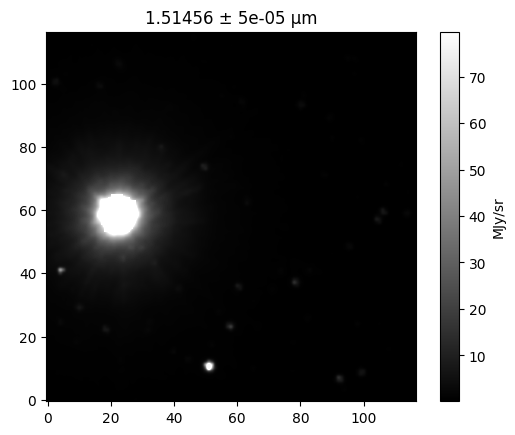

In [102]:
#DISPLAY VIA THE FREQUENCY DOMAIN
import matplotlib.pyplot as plt

%matplotlib inline
print(sorted(round(r["lam"], 5) for r in records))   # look for a value several frames share
print(len(sorted(round(r["lam"], 5) for r in records)))
target_wavelength, tol = 1.51456, 0.00005                 # change to a value from the list above
target_start = 60918
target_end = 66000

sel = [r for r in records if abs(r["lam"] - target_wavelength) <= tol and r["mjd"] >= target_start and r["mjd"] <= target_end]
print(len(sel), "frames in window")

cube = np.array([r["image_r"] for r in sel])
var = np.array([r["var_r"] for r in sel])
valid = np.isfinite(cube) & np.isfinite(var) & (var > 0)

wgt = np.where(valid, 1.0 / np.where(valid, var, 1.0), 0.0)
with np.errstate(invalid="ignore", divide="ignore"):
    stack = np.sum(np.where(valid, cube, 0.0) * wgt, axis=0) / np.sum(wgt, axis=0)

lo, hi = np.nanpercentile(stack, [1, 99.5])
plt.imshow(stack, origin="lower", cmap="gray", vmin=lo, vmax=hi, interpolation="gaussian")
plt.title(f"{target_wavelength} ± {tol} µm")
plt.colorbar(label = "MJy/sr")
plt.show()


In [126]:
#DISPLAY VIA THE TIME DOMAIN, A SERIES OF IMAGES, CAN BOT STORED AND DISPLAYED AS A ANIMATION
print(sorted(r["mjd"] for r in records))  # look for a value several frames share
print(len(sorted(r["lam"] for r in records)))
target_wavelength, tol = 3.0, 0.01                  # change to a value from the list above
target_start = 0.0
target_end = 99999.9

[60918.88041, 60918.88041, 60918.881902, 60918.881902, 60918.883394, 60918.883394, 60918.884887, 60919.699, 60919.699, 60919.700492, 60919.700492, 60919.701985, 60919.701985, 60919.831509, 60919.831509, 60919.969276, 60919.969276, 60919.970768, 60919.970768, 60919.97226, 60919.97226, 60919.973753, 60919.973753, 60921.938075, 60921.938075, 60921.939567, 60922.550361, 60922.550361, 60922.551853, 60922.551853, 60922.617353, 60922.617353, 60922.618845, 60922.618845, 60922.620337, 60926.355629, 60926.355629, 60926.357121, 60926.357121, 60926.358613, 60926.358613, 60926.360105, 60926.360105, 60927.78361, 60927.78361, 60927.785102, 60927.785102, 60927.915674, 60927.915674, 60927.917167, 60927.917167, 60927.918659, 60927.918659, 60927.920151, 60927.920151, 60928.052606, 60928.052606, 60928.054099, 60928.054099, 60928.055591, 60928.057083, 60928.057083, 60928.187176, 60928.187176, 60928.729344, 60928.729344, 60928.730836, 60928.732329, 60928.732329, 60932.330652, 60932.330652, 60932.332144, 609

In [133]:
target_wl = input("Enter Target Wavelength (µm), Default = 3.0: ")
target_tol = input("Enter Wavelength tolerance (µm), Default = 0.1: ")

Enter Target Wavelength (µm), Default = 3.0:  1.1
Enter Wavelength tolerance (µm), Default = 0.1:  0.1


In [134]:
target_wavelength = float(target_wl) if np.isfinite(float(target_wl)) else target_wavelength
tol = float(target_tol) if np.isfinite(float(target_tol)) else tol
print(f"Target Wavelength: {target_wavelength}")
print(f"Target Tol: {tol}")

Target Wavelength: 1.1
Target Tol: 0.1


In [115]:
target_start_in = input("Enter Target Start MJD (Default = 0): ")

Enter Target Start MJD (Default = 0):  60000


In [117]:
target_end_in = input("Enter Target End MJD (Default = 99999): ")

Enter Target End MJD (Default = 99999):  70000


In [130]:
target_start = float(target_start_in) if float(target_start_in) >= target_start and np.isfinite(float(target_start_in)) else target_start
target_end = float(target_end_in) if float(target_end_in) <= target_end and np.isfinite(float(target_end_in)) else target_end
print(f"Target Start MJD: {target_start}")
print(f"Target End MJD: {target_end}")

Target Start MJD: 60000.0
Target End MJD: 70000.0


19 frames in window
5


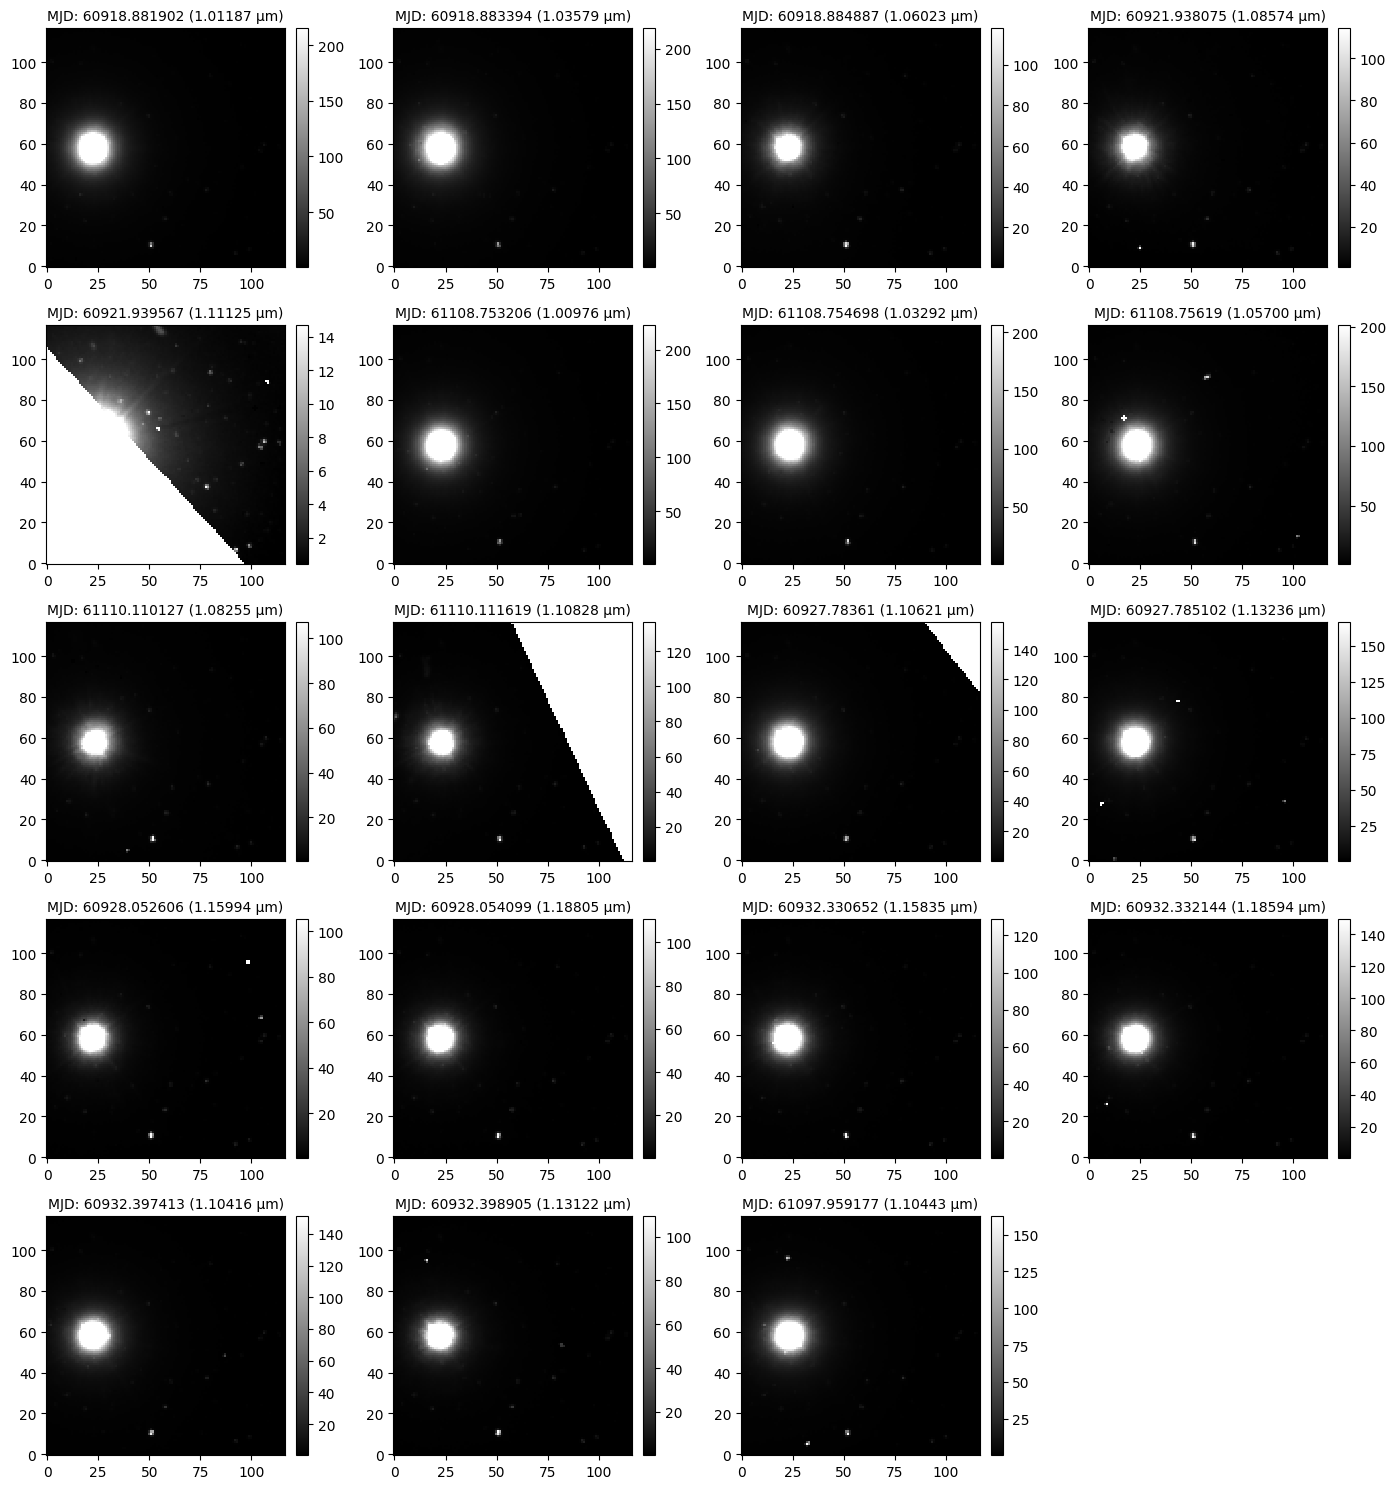

In [135]:
sel = [r for r in records if abs(r["lam"] - target_wavelength) <= tol and r["mjd"] >= target_start and r["mjd"] <= target_end]
print(len(sel), "frames in window")

import math
nbr_images = len(sel)
ncols = 4
# Calculate how many rows
nrows = math.ceil(nbr_images / ncols)
print(nrows)
# Create the dynamic figure grid
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * 3.5, nrows * 3))
if nrows == 1 and ncols == 1:
    axs = np.array([axs])
else:
    axs = axs.flatten()

ii = 0
for r in sel:
    cube = np.array(r["image_r"])
    var = np.array(r["var_r"])
    valid = np.isfinite(cube) & np.isfinite(var) & (var > 0)
    wgt = np.where(valid, 1.0 / np.where(valid, var, 1.0), 0.0)
    with np.errstate(invalid="ignore", divide="ignore"):
        stack = np.where(valid, cube * wgt, 0.0) / wgt

    lo, hi = np.nanpercentile(stack, [1, 99.5])
    im = axs[ii].imshow(stack, origin='lower', cmap='gray', vmin=lo, vmax=hi, interpolation="nearest")
    
    # Label with index and wavelength
    wl = r["lam"]
    mjd = r['mjd']
    axs[ii].set_title(f"MJD: {mjd} ({wl:.5f} µm)", fontsize=10)
    
    fig.colorbar(im, ax=axs[ii], fraction=0.046, pad=0.04)
    ii = ii+1
for jj in range(nbr_images, len(axs)):
    axs[jj].axis('off')

plt.tight_layout()
plt.show()

In [136]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import IntSlider, Play, Button, HBox, VBox, jslink, interactive_output
from IPython.display import display

assert len(sel) > 0, "no frames selected, widen the wavelength or time window"

def frame_image(r):
    img = np.array(r["image_r"], dtype=float)
    lo, hi = np.nanpercentile(img, [1, 99.5])
    return img, lo, hi

def view(i):
    r = sel[i]
    img, lo, hi = frame_image(r)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    im = ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi, interpolation="nearest")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="MJy/sr")
    ax.set_title(f"{i+1}/{len(sel)}   MJD {r['mjd']:.3f}   ({r['lam']:.4f} µm)", fontsize=10)
    plt.show()
    plt.close(fig)

slider = IntSlider(min=0, max=len(sel) - 1, step=1, value=0, description="Frame", continuous_update=False)
play = Play(min=0, max=len(sel) - 1, step=1, value=0, interval=700)
jslink((play, "value"), (slider, "value"))

prev_btn = Button(description="Previous", icon="step-backward")
next_btn = Button(description="Next", icon="step-forward")

def step(delta):
    slider.value = (slider.value + delta) % len(sel)       # wraps around at both ends

prev_btn.on_click(lambda b: step(-1))
next_btn.on_click(lambda b: step(+1))

# Disable the step buttons while the animation is playing (only if this ipywidgets version reports it)
if "playing" in play.trait_names():
    def on_playing(change):
        prev_btn.disabled = next_btn.disabled = bool(change["new"])
    play.observe(on_playing, names="playing")

out = interactive_output(view, {"i": slider})
display(VBox([HBox([play, prev_btn, next_btn, slider]), out]))